Estimate a shared set of CMR parameters from participants' recorded recalls in the war-photo-recall experiment. Save the fit, generate simulated recalls and compare the model's behavior with the observations. The simulation and parameter-exploration templates build on the result of this procedure.

## Parameters and setup

The tagged **parameters** cell contains the defaults for one run. Edit them here, or supply replacements through Quarto or Papermill. The following cell imports the tools and prepares paths from the resulting values.

Give independent jobs different `output_dir` values to keep their results separate. The discussion and saved results below describe the default example.

In [1]:
#| code-summary: "Set the parameters for this run"

data_path = "data/Dupertuys2026.h5"
output_dir = "results/fitting"

confidence_level = 0.95
optimizer = "scipy"  # "scipy" or "evosax"; the workflow below is shared.
fit_seed = 0
simulation_seed = 1
simulation_repetitions = 10
fit_filename = "Dupertuys2026_CMR_demo.json"
free_bounds = {"encoding_drift_rate": [0.05, 0.95], "recall_drift_rate": [0.05, 0.95]}
search_settings = {
    "num_steps": 30, "pop_size": 8, "best_of": 1,
    "polish": False, "progress_bar": False,
}

# Baseline values; free_bounds determines which are fitted.
base_params = {
    "encoding_drift_rate": 0.7,
    "start_drift_rate": 0.6,
    "recall_drift_rate": 0.85,
    "learning_rate": 0.4,
    "primacy_scale": 8.0,
    "primacy_decay": 1.0,
    "item_support": 6.0,
    "shared_support": 0.02,
    "choice_sensitivity": 1.5,
    "learn_after_context_update": False,
    "allow_repeated_recalls": False,
}
plot_seed = 0  # NumPy seed for bootstrap displays.


In [2]:
#| code-summary: "Import packages and fitting tools"

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import jax.numpy as jnp
from jaxcmr.helpers import load_data

plt.rcParams.update({"figure.figsize": (7, 4), "figure.dpi": 120})

import json
import hashlib
import jax
import jaxcmr
from jaxcmr.components import context, linear_memory
from jaxcmr.components.termination import NoStopTermination
from jaxcmr.models.cmr import make_factory
from jaxcmr.helpers import save_dict_to_hdf5
from jaxcmr.simulation import simulate_h5_from_h5, simulate_study_free_recall_and_forced_stop
from jaxcmr.analyses.spc import plot_spc
from jaxcmr.analyses.pnr import plot_pnr
from jaxcmr.analyses.crp import plot_crp

jax.config.update("jax_enable_x64", True)

from jaxcmr.fitting import ScipyDE, EvosaxDE
from jaxcmr.loss.transform_sequence_likelihood import ExcludeTerminationLikelihoodLoss

# Resolve paths and derived settings after parameter overrides.
data_path = Path(data_path)
output_dir = Path(output_dir)
fit_path = output_dir / fit_filename
search_settings = {**search_settings, "seed": fit_seed}
np.random.seed(plot_seed)
output_dir.mkdir(parents=True, exist_ok=True)

## Load the observations and choose what to fit

All three list conditions enter this example. **Pooled** fitting estimates one parameter set
for the combined observations; it does not estimate a separate set for each participant.
There are only four lists per participant, so fitting many individual parameters would be a
poor introductory default. Participant identities are retained for simulations and summaries.

The padded study slot in one list remains in the input representation. Zero study codes are
ignored by the model, and observed recall codes are mapped through their study positions.
For the fixed-length comparison figures, both observed and simulated data subsequently select
complete 12-item lists.

In [3]:
#| code-summary: "Load and select the observed recalls"

data = load_data(str(data_path))
list_type = np.asarray(data["list_type"]).ravel()
subjects = np.asarray(data["subject"]).ravel()
presentations = np.asarray(data["pres_itemnos"])
complete = np.all(presentations > 0, axis=1)
conditions = {1: "Mixed", 2: "Pure emotional", 3: "Pure neutral"}
print(f"Loaded {len(list_type)} lists from {len(np.unique(subjects))} participants.")

trial_mask = jnp.asarray(list_type >= 1)
trial_indices = jnp.flatnonzero(trial_mask)
print(f"Fitting one shared parameter set to {int(trial_mask.sum())} lists.")

Loaded 492 lists from 123 participants.
Fitting one shared parameter set to 492 lists.


## Specify the model and objective

This example fits ordinary CMR to **recall order conditional on the observed response count**.
`NoStopTermination` disables model-generated stopping; the loss scores nonzero recall events.
The later simulations are forced to the corresponding observed lengths. Agreement in recall
length is therefore supplied to the model, not evidence that it predicts when recall ends.

The baseline values in the parameters cell come from the README example, with the unused stopping parameters
omitted. Only encoding drift and recall drift are free. All other assumptions remain visible.
The reduced search demonstrates the procedure; it is not a full scientific fit or parameter-recovery exercise.

In [4]:
#| code-summary: "Construct the CMR model factory"

model_factory = make_factory(
    mfc_create_fn=linear_memory.init_mfc,
    mcf_create_fn=linear_memory.init_mcf,
    context_create_fn=context.init,
    termination_policy_create_fn=NoStopTermination,
)

## Fit the selected observations

The population multiplier of eight gives 16 candidate parameter vectors for this two-parameter
search. The search is capped at 30 generations, uses one restart and disables final polishing.
Its convergence flag reports the optimizer's stopping criterion, not scientific adequacy.
The first call also compiles numerical calculations, so it can take longer than a repeated run.

The other differential-evolution notebooks follow this same procedure. Evosax is available through
the setting above. Map/Scan variants change scheduling across separate subject fits; they do not
add a different research procedure to this pooled example.

In [5]:
#| code-summary: "Fit the two free parameters"

fitter_class = {"scipy": ScipyDE, "evosax": EvosaxDE}[optimizer]
fitter = fitter_class(data, None, base_params, model_factory, ExcludeTerminationLikelihoodLoss,
                      hyperparams={**search_settings, "bounds": free_bounds})
result = fitter.fit(trial_mask, subject_id=-1)
display(pd.DataFrame({"Parameter": list(free_bounds),
                      "Baseline": [base_params[name] for name in free_bounds],
                      "Fitted": [result["fits"][name][0] for name in free_bounds]}))
print("Generations:", result.get("nit"), "Optimizer convergence flag:", result.get("converged"))

/Users/jordangunn/Codex/2026-11-09/oka/work/vendor-simple-pytree/venv/lib/python3.12/site-packages/scipy/optimize/_differentialevolution.py:518: UserWarning: differential_evolution: the 'vectorized' keyword has overridden updating='immediate' to updating='deferred'
  with DifferentialEvolutionSolver(func, bounds, args=args,


,Parameter,Baseline,Fitted
0,encoding_drift_rate,0.70,0.573109
1,recall_drift_rate,0.85,0.479808


Generations: [6] Optimizer convergence flag: [True]


## Recalculate the objective and save the result

Evaluate the observed sequences again using the returned parameters. The two displayed negative
log likelihoods refer to the same observations and parameter values. Store the selection and
model configuration with the fit so a later simulation can use the same interpretation.

In [6]:
#| code-summary: "Recalculate the objective and save the fit"

loss = ExcludeTerminationLikelihoodLoss(model_factory, data, None)
free_names = tuple(free_bounds)
returned = jnp.asarray([result["fits"][name][0] for name in free_names])[:, None]
recomputed_nll = float(jax.jit(lambda x: loss(trial_indices, base_params, free_names, x))(returned)[0])
display(pd.DataFrame({"Objective": ["Returned by fitter", "Recalculated from parameters"],
                      "Negative log likelihood": [result["fitness"][0], recomputed_nll]}))
result["fixed"] = {name: value for name, value in base_params.items() if name not in free_bounds}
result.update({
    "baseline_parameters": base_params,
    "name": "Dupertuys pooled CMR demonstration", "model": "CMR", "pooled": True,
    "data_tag": "Dupertuys2026", "data_query": "list_type >= 1",
    "data_sha256": hashlib.sha256(data_path.read_bytes()).hexdigest(),
    "selected_trial_indices": np.asarray(trial_indices).tolist(),
    "model_factory": "jaxcmr.models.cmr.make_factory",
    "components": {"mfc_create_fn": "jaxcmr.components.linear_memory.init_mfc",
                   "mcf_create_fn": "jaxcmr.components.linear_memory.init_mcf",
                   "context_create_fn": "jaxcmr.components.context.init",
                   "termination_policy_create_fn": "jaxcmr.components.termination.NoStopTermination"},
    "loss_function": "jaxcmr.loss.transform_sequence_likelihood.ExcludeTerminationLikelihoodLoss",
    "simulation_function": "jaxcmr.simulation.simulate_study_free_recall_and_forced_stop",
    "recomputed_nll": recomputed_nll, "jaxcmr_version": jaxcmr.__version__,
    "simulation_seed": simulation_seed, "simulation_repetitions": simulation_repetitions,
    "example_note": "Two free parameters; a capped demonstration, not a claim of a converged scientific fit.",
})
fit_path.write_text(json.dumps(result, indent=2) + "\n")
print("Saved fit:", fit_path)

,Objective,Negative log likelihood
0,Returned by fitter,8070.178342
1,Recalculated from parameters,8070.178342


Saved fit: results/fitting/Dupertuys2026_CMR_demo.json


## Simulate from the shared parameters

The fit uses subject label -1 to denote pooling. Simulation still needs the actual participant
identifiers: repeat the shared parameter values over those identifiers, keeping their study lists
and conditions. Restore the two Boolean switches from the fit file's numeric representation.
Every execution of this cell generates fresh simulations from the current result;
it never silently loads an older simulation after a new fit.

In [7]:
#| code-summary: "Simulate recalls for the original participants"

participant_ids = jnp.unique(data["subject"].ravel())
simulation_parameters = {
    name: jnp.repeat(jnp.asarray(values), len(participant_ids))
    for name, values in result["fits"].items() if name != "subject"
}
simulation_parameters["subject"] = participant_ids
for name in ("allow_repeated_recalls", "learn_after_context_update"):
    simulation_parameters[name] = simulation_parameters[name].astype(bool)

simulated = simulate_h5_from_h5(
    model_factory, data, None, simulation_parameters, trial_mask,
    experiment_count=simulation_repetitions, rng=jax.random.PRNGKey(simulation_seed),
    simulate_trial_fn=simulate_study_free_recall_and_forced_stop,
)
simulation_path = output_dir / "simulated_recalls.h5"
save_dict_to_hdf5(simulated, str(simulation_path))
print(f"Saved {len(simulated['subject'])} simulated lists to {simulation_path}")

Saved 4920 simulated lists to results/fitting/simulated_recalls.h5


## Compare model and observations

Apply the same complete-list selection and analyses to both response datasets. Simulations
include ten repetitions of each selected list, so their trial mask must be constructed from
their own arrays. Intervals describe participant summaries, not uncertainty in the fitted parameters.

/Users/jordangunn/Codex/2026-11-09/oka/work/vendor-simple-pytree/venv/lib/python3.12/site-packages/scipy/_lib/_util.py:306: DegenerateDataWarning: The BCa confidence interval cannot be calculated. This problem is known to occur when the distribution is degenerate or the statistic is np.min.
  return fun(*args, **kwargs)


/Users/jordangunn/Codex/2026-11-09/oka/work/vendor-simple-pytree/venv/lib/python3.12/site-packages/scipy/_lib/_util.py:306: DegenerateDataWarning: The BCa confidence interval cannot be calculated. This problem is known to occur when the distribution is degenerate or the statistic is np.min.
  return fun(*args, **kwargs)


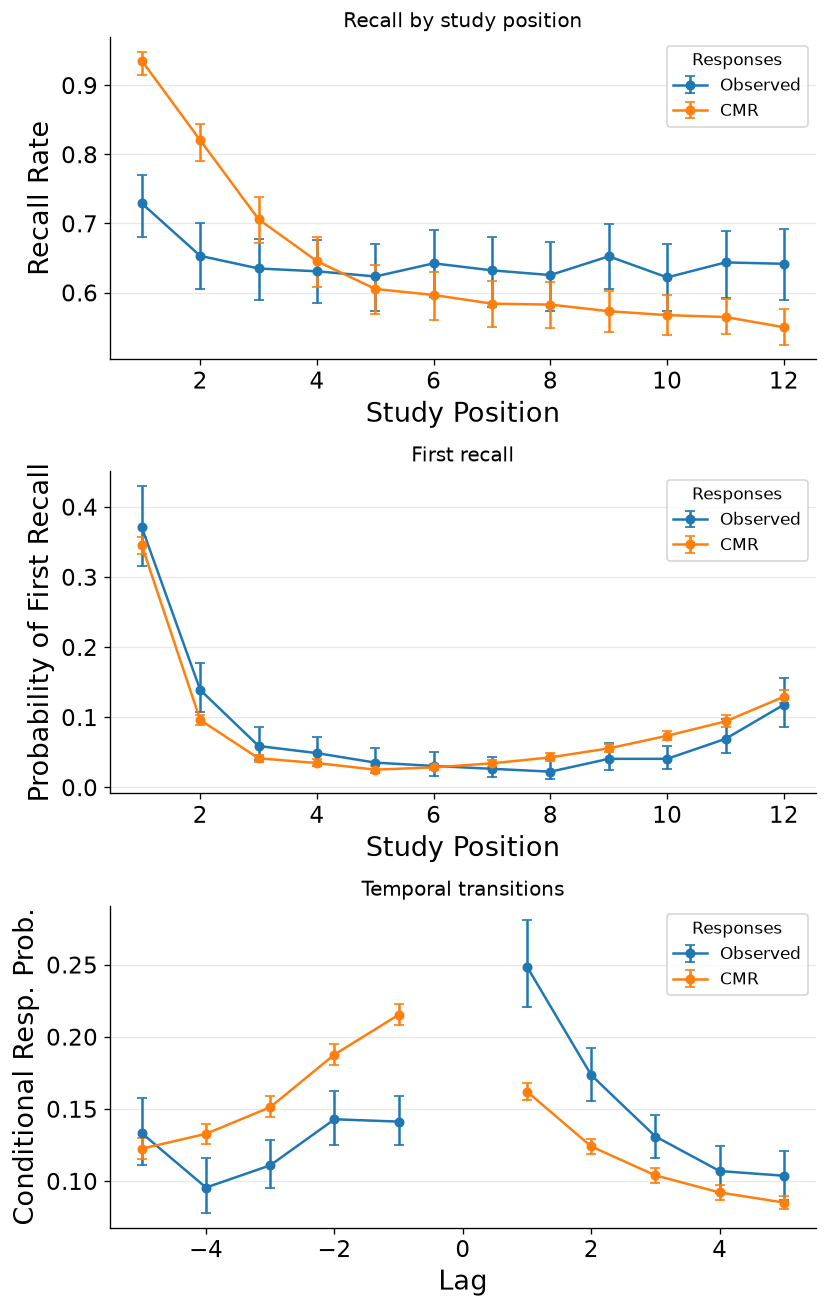

In [8]:
#| code-summary: "Plot observed and simulated behavior"

observed_mask = trial_mask & jnp.all(data["pres_itemnos"] > 0, axis=1)
simulated_mask = jnp.all(simulated["pres_itemnos"] > 0, axis=1)
fig, axes = plt.subplots(3, 1, figsize=(7, 11))
plot_spc([data, simulated], [observed_mask, simulated_mask],
         labels=["Observed", "CMR"], contrast_name="Responses", confidence_level=confidence_level, axis=axes[0])
plot_pnr([data, simulated], [observed_mask, simulated_mask], query_recall_position=0,
         labels=["Observed", "CMR"], contrast_name="Responses", confidence_level=confidence_level, axis=axes[1])
plot_crp([data, simulated], [observed_mask, simulated_mask], max_lag=5,
         labels=["Observed", "CMR"], contrast_name="Responses", confidence_level=confidence_level, axis=axes[2])
for ax, title in zip(axes, ("Recall by study position", "First recall", "Temporal transitions")):
    ax.set_title(title)
fig.tight_layout()
fig.savefig(output_dir / "model_and_data.png", dpi=160)
plt.show()

## Interpret and use another specification

The saved example exaggerates the SPC's early-position advantage and misses the observed
forward-transition peak near lag +1. These are concrete targets for further model development.
A better likelihood
does not guarantee agreement with every summary. This short run is intended to expose the steps
and editable assumptions, not establish the best possible CMR account of these results.

Change `free_bounds`, the fixed values, the selection or the optimizer settings to address another
question. Keep model, loss and simulation stopping assumptions consistent. When rerunning, run all
dependent cells after fitting so the saved fit, simulations and figures correspond to one another.

The outputs are the fit JSON, `simulated_recalls.h5` and `model_and_data.png` in `results/fitting/`.
The **Simulation** template can read this fit directly; a supplied copy also lets you start there.